**environment setup and data loading**

In [1]:
from google.colab import drive

# connect to drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
FOLDER_PATH = '/content/drive/MyDrive/loans_ligitation/'

# load datasets
loans = pd.read_csv(FOLDER_PATH + 'loan_month_recovery.csv')
features = pd.read_csv(FOLDER_PATH + 'Features.csv')
dict_df = pd.read_csv(FOLDER_PATH + 'feature_dictionary.csv')

In [4]:
# standardize primary key
features = features.rename(columns={'client_key': 'CLIENT_KEY'})

In [5]:
# feature mapping
feat_map = dict(zip(dict_df['column'], dict_df['description']))

In [6]:
print("datasets:")
print(f"- loans shape: {loans.shape}")
print(f"- features shape: {features.shape}")
print(f"- feature dictionary: {len(feat_map)} feature descriptions mapped")

datasets:
- loans shape: (70173, 33)
- features shape: (29763, 52)
- feature dictionary: 50 feature descriptions mapped


**data quality checking**

In [7]:
M_cols = [f'M{i:02d}_PAID' for i in range(1, 25)]

In [8]:
assert not features.duplicated(['CLIENT_KEY', 'PERIOD']).any(), "Error: Duplicate CLIENT_KEY and PERIOD combinations found in features!"

assert loans.LOAN_KEY.is_unique, "Error: LOAN_KEY values are not unique!"

assert (loans[M_cols].fillna(0) >= 0).all().all(), "Error: Negative payment values found in payment columns!"
assert (loans[M_cols].notna().sum(axis=1) == loans.MONTHS_OBSERVED).all(), "Error: Non-null payment counts do not match MONTHS_OBSERVED!"

currency check


In [9]:
ccy_check = loans.assign(
    ratio = loans['OUTST_AT_TRIAL'] / loans['DEAL_PRINCIPAL_IN_GEL']
).groupby('DEAL_CCY')['ratio'].mean()

In [10]:
print("--- Mean OUTST / PRINCIPAL Ratio by Currency ---")
print(ccy_check)
print("\nConclusion: USD and GEL ratios are virtually identical (~0.72 vs ~0.74). USD balances are already converted to GEL and remain fully in scope.")

--- Mean OUTST / PRINCIPAL Ratio by Currency ---
DEAL_CCY
GEL    0.743693
USD    0.724854
Name: ratio, dtype: float64

Conclusion: USD and GEL ratios are virtually identical (~0.72 vs ~0.74). USD balances are already converted to GEL and remain fully in scope.


In [11]:
print(loans.groupby('DEAL_CCY')[['DEAL_PRINCIPAL_IN_GEL', 'OUTST_AT_TRIAL']].median())

          DEAL_PRINCIPAL_IN_GEL  OUTST_AT_TRIAL
DEAL_CCY                                       
GEL                    2236.650        1635.240
USD                    4982.445        3830.805


In [12]:
feature_cols = [c for c in features.columns if c.startswith('feature_')]
assert set(feature_cols) == set(dict_df['column']), "Error: Feature columns and dictionary do not match!"

In [13]:
unit_issues = []
for _, row in dict_df.iterrows():
    s = features[row['column']].dropna()
    if row['unit'] == 'ratio 0-1' and not (s.min() >= 0 and s.max() <= 1):
        unit_issues.append((row['column'], 'ratio outside [0, 1]'))
    if row['unit'] == '0/1' and not set(s.unique()) <= {0, 1}:
        unit_issues.append((row['column'], 'not binary'))
    if row['unit'] in ('GEL', 'count') and (s < 0).any():
        unit_issues.append((row['column'], 'negative values'))

print("--- Unit Compliance Check ---")
print("Unit issues:", unit_issues if unit_issues else "None (100% compliant)")

--- Unit Compliance Check ---
Unit issues: None (100% compliant)


leakage

In [14]:
# Target Leakage Candidates ('after' in description)
leak_candidates = dict_df[dict_df['description'].str.contains(r'\bafter\b', case=False)]
print("--- Target Leakage Candidates ---")
print(leak_candidates[['column', 'description']].to_string(index=False))

--- Target Leakage Candidates ---
     column                                                                                                                          description
feature_045 Payment-arrangement and restructuring requests registered on the client's collections file in the 12 months after enforcement start.


missing values

--- MISSING VALUES (missing_share > 0) ---
feature_011    0.862
feature_039    0.306
dtype: float64


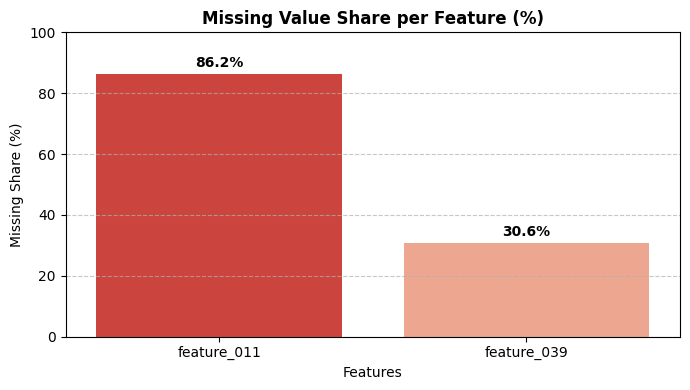

In [15]:
# MISSING VALUES PROFILE
feature_cols = [c for c in features.columns if c.startswith('feature_')]

missing_share = features[feature_cols].isna().mean()
missing_features = missing_share[missing_share > 0].sort_values(ascending=False)

print("--- MISSING VALUES (missing_share > 0) ---")
if not missing_features.empty:
    print(missing_features.round(3))

    # ------------------ VISUALIZATION ------------------
    plt.figure(figsize=(7, 4))
    ax = sns.barplot(
          x=missing_features.index,
          y=missing_features.values * 100,
          hue=missing_features.index,
          palette='Reds_r',
          legend=False)

    plt.title('Missing Value Share per Feature (%)', fontsize=12, fontweight='bold')
    plt.ylabel('Missing Share (%)', fontsize=10)
    plt.xlabel('Features', fontsize=10)
    plt.ylim(0, 100)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    for p in ax.patches:
        height = p.get_height()
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

    plt.tight_layout()
    plt.show()
    # ---------------------------------------------------
else:
    print("No missing values found (100% complete dataset)")

--- ZERO / LOW VARIANCE FEATURES (n_unique <= 2) ---
feature_050    1
feature_027    2
feature_042    2
feature_030    2
feature_049    2
dtype: int64


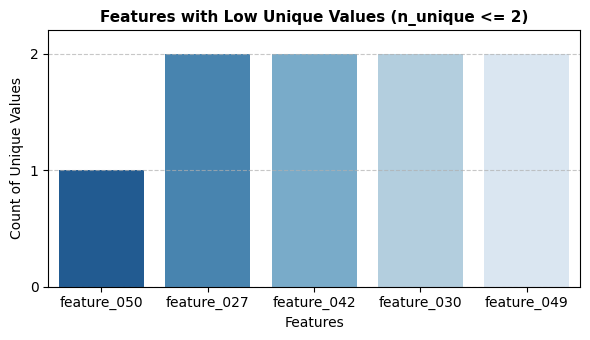

In [16]:
# UNIQUE VALUES PROFILE (n_unique <= 2)
import matplotlib.pyplot as plt
import seaborn as sns

feature_cols = [c for c in features.columns if c.startswith('feature_')]

# Calculate number of unique values for each feature
n_unique = features[feature_cols].nunique()

# Filter features with 2 or fewer unique values
low_var_features = n_unique[n_unique <= 2].sort_values()

print("--- ZERO / LOW VARIANCE FEATURES (n_unique <= 2) ---")
if not low_var_features.empty:
    print(low_var_features)

    # ------------------ VISUALIZATION ------------------
    plt.figure(figsize=(6, 3.5))
    ax = sns.barplot(
        x=low_var_features.index,
        y=low_var_features.values,
        hue=low_var_features.index,
        palette='Blues_r',
        legend=False
    )

    plt.title('Features with Low Unique Values (n_unique <= 2)', fontsize=11, fontweight='bold')
    plt.ylabel('Count of Unique Values', fontsize=10)
    plt.xlabel('Features', fontsize=10)
    plt.ylim(0, 2.2)
    plt.yticks([0, 1, 2])
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()
    # ---------------------------------------------------
else:
    print("All features have normal variance (n_unique > 2)")

--- TOP VALUE SHARE FOR ALL LOW-VARIANCE FEATURES (%) ---
feature_050    100.0%
feature_030    99.57%
feature_042    73.77%
feature_027    72.31%
feature_049    57.76%
dtype: object


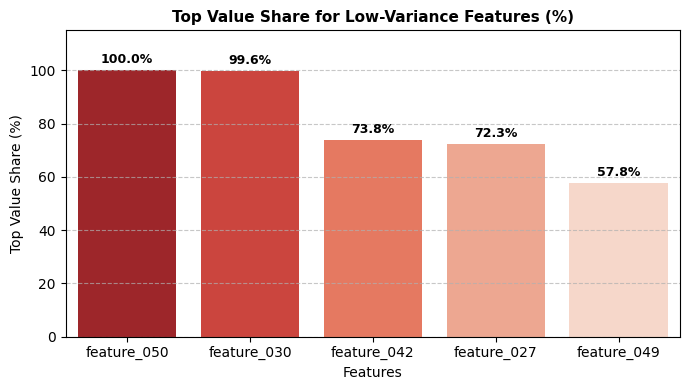

In [17]:
# TOP VALUE SHARE FOR ALL LOW-VARIANCE FEATURES

low_var_cols = low_var_features.index

top_shares = features[low_var_cols].apply(
    lambda s: s.value_counts(normalize=True).iloc[0]
) * 100

top_shares = top_shares.sort_values(ascending=False)

print("--- TOP VALUE SHARE FOR ALL LOW-VARIANCE FEATURES (%) ---")
print(top_shares.round(2).astype(str) + '%')

# ------------------ VISUALIZATION ------------------
plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=top_shares.index,
    y=top_shares.values,
    hue=top_shares.index,
    palette='Reds_r',
    legend=False
)

plt.title('Top Value Share for Low-Variance Features (%)', fontsize=11, fontweight='bold')
plt.ylabel('Top Value Share (%)', fontsize=10)
plt.xlabel('Features', fontsize=10)
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3),
                textcoords='offset points')

plt.tight_layout()
plt.show()

duplicate features

In [18]:
# DUPLICATE FEATURES SCAN

feature_cols = [c for c in features.columns if c.startswith('feature_')]

dup_pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        col1 = feature_cols[i]
        col2 = feature_cols[j]
        # including NaNs
        if features[col1].equals(features[col2]):
            dup_pairs.append((col1, col2))

print("--- DUPLICATE FEATURES SCAN ---")
if dup_pairs:
    for col1, col2 in dup_pairs:
        print(f" -> MATCH FOUND: '{col2}' is 100% IDENTICAL to '{col1}'")
else:
    print("No exact duplicate columns found.")

--- DUPLICATE FEATURES SCAN ---
 -> MATCH FOUND: 'feature_033' is 100% IDENTICAL to 'feature_017'


In [19]:
# HIGH CORRELATION SCAN (r > 0.99) - FIXED


feature_cols = [c for c in features.columns if c.startswith('feature_')]

corr_matrix = features[feature_cols].corr().abs()

upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

high_corr = upper_tri.unstack().dropna()
high_corr_pairs = high_corr[high_corr > 0.99]

print("--- HIGH CORRELATION PAIRS (r > 0.99) ---")
if not high_corr_pairs.empty:
    for (col2, col1), val in high_corr_pairs.items():
        print(f" -> HIGH CORRELATION: '{col1}' and '{col2}' (r = {val:.4f})")
else:
    print("No highly correlated pairs (r > 0.99) found.")

--- HIGH CORRELATION PAIRS (r > 0.99) ---
 -> HIGH CORRELATION: 'feature_017' and 'feature_033' (r = 1.0000)


In [20]:
# INFINITE VALUES CHECK (np.inf / -np.inf)

inf_check = np.isinf(features[feature_cols].select_dtypes(include=[np.number])).sum()
inf_cols = inf_check[inf_check > 0]

print("--- INFINITE VALUES CHECK ---")
if not inf_cols.empty:
    print("WARNING: Infinite values found in columns:")
    print(inf_cols)
else:
    print("Clean: No infinite (inf / -inf) values found in any feature.")

--- INFINITE VALUES CHECK ---
Clean: No infinite (inf / -inf) values found in any feature.


In [21]:
assert features['feature_017'].equals(features['feature_033']), "feature_033 is not identical to feature_017!"

In [22]:
# REGISTER DROP CANDIDATES & ACTIVE FEATURE LIST

# Register drop candidates
DROP_CANDIDATES = {
    'feature_050': 'Constant feature (100% single unique value)',
    'feature_030': 'Near-constant feature (99.57% top value share)',
    'feature_033': 'Exact duplicate of feature_017 (verified programmatically)',
    'feature_045': 'Target leakage (reflects 12-month post-enforcement state)'
}

# Define active feature column list for modeling without physical deletion
all_feature_cols = [c for c in features.columns if c.startswith('feature_')]
active_feature_cols = [c for c in all_feature_cols if c not in DROP_CANDIDATES]

print("--- STEP A: PRUNING REGISTRY COMPLETE ---")
print(f"Total Raw Features:            {len(all_feature_cols)}")
print(f"Active Features for Modeling: {len(active_feature_cols)}")
print(f"Registered Drop Candidates:    {len(DROP_CANDIDATES)}")

--- STEP A: PRUNING REGISTRY COMPLETE ---
Total Raw Features:            50
Active Features for Modeling: 46
Registered Drop Candidates:    4


In [23]:
# Sum 24-month paid recovery at loan level
# M_cols = [f'M{i:02d}_PAID' for i in range(1, 25)]
loans['paid_total'] = loans[M_cols].sum(axis=1)

# Aggregate loans to Client-Period level
clients = loans.groupby(['CLIENT_KEY', 'PERIOD']).agg(
    out=('OUTST_AT_TRIAL', 'sum'),
    principal=('DEAL_PRINCIPAL_IN_GEL', 'sum'),
    n_loans=('LOAN_KEY', 'size'),
    any_collateral=('HAS_COLLATERAL', 'max'),
    all_collateral=('HAS_COLLATERAL', 'min'),
    paid=('paid_total', 'sum'),
    months_obs=('MONTHS_OBSERVED', 'first')
).reset_index()

# Merge with raw features dataframe
clients = clients.merge(features, on=['CLIENT_KEY', 'PERIOD'], how='left', validate='1:1')

# Scope Funnel Breakdown
funnel = pd.Series({
    'Total Client-Periods': len(clients),
    'Pure Unsecured (IN SCOPE)': (clients.any_collateral == 0).sum(),
    'Mixed Collateral': ((clients.any_collateral == 1) & (clients.all_collateral == 0)).sum(),
    'Fully Secured': (clients.all_collateral == 1).sum()
})

print("--- SCOPE FUNNEL BREAKDOWN ---")
print(funnel.to_string())

# Isolate Active Pure Unsecured Scope (OUTST > 0)
scope = clients[(clients.any_collateral == 0) & (clients.out > 0)].copy()
print(f"\nFinal Active Scope Size: {len(scope):,} client-periods")

# Check Observation Period Distribution
print("\n--- DISTRIBUTION OF MONTHS OBSERVED IN ACTIVE SCOPE ---")
print(scope['months_obs'].value_counts().sort_index(ascending=False).to_string())

--- SCOPE FUNNEL BREAKDOWN ---
Total Client-Periods         29763
Pure Unsecured (IN SCOPE)    23170
Mixed Collateral              3861
Fully Secured                 2732

Final Active Scope Size: 23,170 client-periods

--- DISTRIBUTION OF MONTHS OBSERVED IN ACTIVE SCOPE ---
months_obs
24    9896
23     634
22     672
21     683
20     665
19     709
18     667
17     678
16     730
15     730
14     747
13     764
12     765
11     791
10     757
9      823
8      786
7      832
6      841


In [24]:
# TARGET DEFINITION & COURT COST ECONOMICS

# Court cost standard: 500 GEL fixed + 10% of outstanding balance
FIXED_COST, PCT_COST = 500, 0.10

scope['cost'] = FIXED_COST + PCT_COST * scope['out']
scope['net'] = scope['paid'] - scope['cost']             # Net profit if we sue
scope['rr'] = scope['paid'] / scope['out']               # Recovery rate
scope['breakeven_rr'] = scope['cost'] / scope['out']     # Recovery rate needed to break even

# Isolate fully observed mature cohort (24 months) vs right-censored partial
mature = scope[scope['months_obs'] == 24].copy()
partial = scope[scope['months_obs'] < 24].copy()

print("--- COHORT OBSERVED BREAKDOWN ---")
print("Mature (24m observed) :", len(mature), f"({len(mature) / len(scope):.1%} of scope)")
print("Partially observed    :", len(partial))

print("\n--- TARGET SUMMARY (MATURE COHORT) ---")
print(mature[['out', 'paid', 'rr', 'net']].describe(percentiles=[.5, .9, .99]).round(2))

print("\nZero recovery share                     :", round((mature['paid'] == 0).mean(), 3))
print("Profitable share (net > 0)              :", round((mature['net'] > 0).mean(), 3))
print("Net if we sue everyone (Baseline)       : GEL", f"{round(mature['net'].sum()):,}")
print("Net if we sue only winners (Oracle)     : GEL", f"{round(mature.loc[mature['net'] > 0, 'net'].sum()):,}")

print("\nMean RR -> mature:", round(mature['rr'].mean(), 3), "| partial:", round(partial['rr'].mean(), 3))

--- COHORT OBSERVED BREAKDOWN ---
Mature (24m observed) : 9896 (42.7% of scope)
Partially observed    : 13274

--- TARGET SUMMARY (MATURE COHORT) ---
             out       paid       rr        net
count    9896.00    9896.00  9896.00    9896.00
mean     7426.37     814.64     0.11    -428.00
std      8797.98    2830.28     0.21    2615.78
min        35.67       0.00     0.00  -16898.22
50%      4865.53       0.00     0.00    -784.83
90%     16516.10    2364.97     0.47    1150.94
99%     42275.33   11992.39     0.84    9409.00
max    180542.79  117016.66     0.98  100379.02

Zero recovery share                     : 0.545
Profitable share (net > 0)              : 0.168
Net if we sue everyone (Baseline)       : GEL -4,235,475
Net if we sue only winners (Oracle)     : GEL 4,966,103

Mean RR -> mature: 0.108 | partial: 0.074


--- CUMULATIVE RECOVERY SHARE (Months 3, 6, 12, 18) ---
Share of 24M total reached: [0.218 0.412 0.714 0.912]


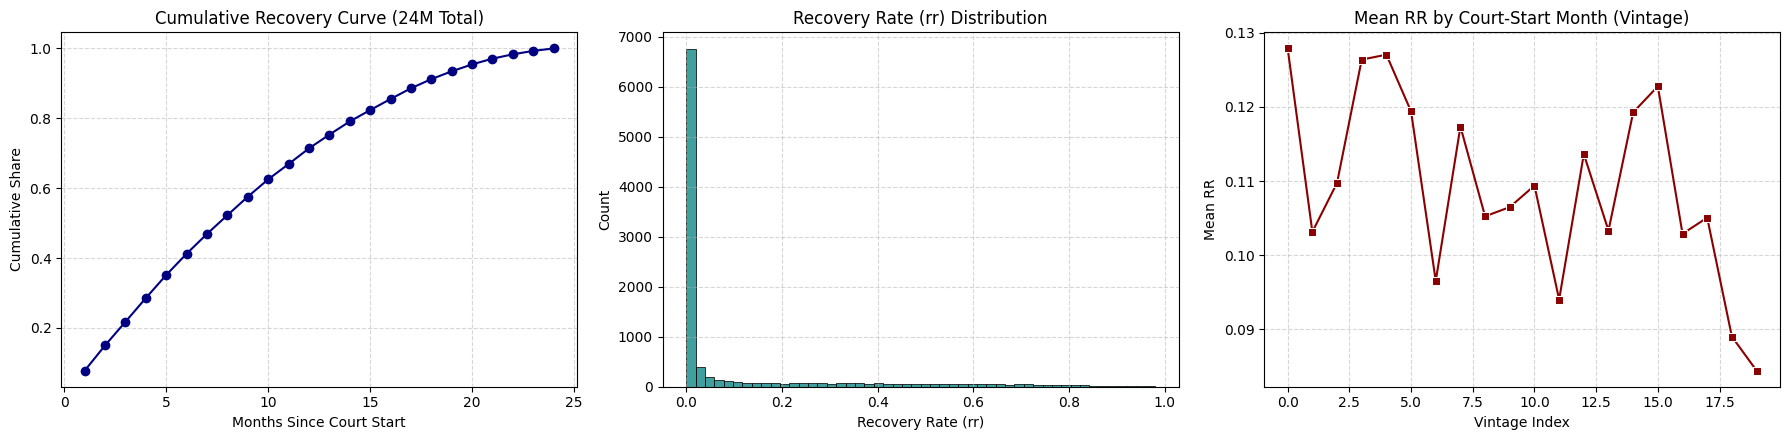

In [25]:
# CUMULATIVE RECOVERY CURVE & VINTAGE DIAGNOSTICS

# Cumulative recovery curve on mature cases
M_cols = [f'M{i:02d}_PAID' for i in range(1, 25)]
merged = loans.merge(mature[['CLIENT_KEY', 'PERIOD']], on=['CLIENT_KEY', 'PERIOD'])
monthly_total = merged[M_cols].sum()
curve = monthly_total.cumsum() / monthly_total.sum()

print("--- CUMULATIVE RECOVERY SHARE (Months 3, 6, 12, 18) ---")
print("Share of 24M total reached:", curve.iloc[[2, 5, 11, 17]].round(3).values)

# Recovery stability across court start months (vintage)
vintage = mature.groupby('PERIOD')['rr'].mean()

# Visualization
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Recovery Curve
ax[0].plot(range(1, 25), curve.values, marker='o', color='navy')
ax[0].set(title='Cumulative Recovery Curve (24M Total)', xlabel='Months Since Court Start', ylabel='Cumulative Share')
ax[0].grid(True, linestyle='--', alpha=0.5)

# 2. Recovery Rate Distribution
sns.histplot(mature['rr'], bins=50, ax=ax[1], color='teal')
ax[1].set(title='Recovery Rate (rr) Distribution', xlabel='Recovery Rate (rr)')
ax[1].grid(True, linestyle='--', alpha=0.5)

# 3. Vintage Analysis
sns.lineplot(x=range(len(vintage)), y=vintage.values, ax=ax[2], color='darkred', marker='s')
ax[2].set(title='Mean RR by Court-Start Month (Vintage)', xlabel='Vintage Index', ylabel='Mean RR')
ax[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

fisher's test for dropping feature_030

In [26]:
# FISHER'S EXACT TEST FOR FEATURE_030
from scipy.stats import fisher_exact

# Fisher's test between feature_030 values and target profitability
ct = pd.crosstab(mature['feature_030'], mature['net'] > 0)
oddsratio, p_value = fisher_exact(ct)

print("--- FISHER'S EXACT TEST FOR FEATURE_030 ---")
print("Contingency Table (feature_030 vs Profitable):")
print(ct)
print(f"\nFisher's Exact Test p-value: {p_value:.4f}")

# Update DROP_CANDIDATES registry with exact statistical evidence
DROP_CANDIDATES['feature_030'] = f"Near-constant (99.57% single value; mature cases with value 1 p={p_value:.3f})"

--- FISHER'S EXACT TEST FOR FEATURE_030 ---
Contingency Table (feature_030 vs Profitable):
net          False  True 
feature_030              
0             8194   1659
1               38      5

Fisher's Exact Test p-value: 0.5380


In [27]:
# FEATURE ENGINEERING & STRICT CLIENT-DISJOINT OOT SPLIT

def add_fe(df):
    df = df.copy()
    # Structural missing indicator for deposit balance
    df['has_deposit'] = df['feature_011'].notna().astype(int)
    df['feature_011'] = df['feature_011'].fillna(0)
    # Log transformation for balance scale adjustment
    df['log_out'] = np.log1p(df['out'])
    return df

mature = add_fe(scope[scope['months_obs'] == 24])

# Clean features (raw data approach)
FEATS = active_feature_cols + ['out', 'log_out', 'n_loans', 'has_deposit']

# Initial Out-Of-Time Split
train = mature[mature['PERIOD'] <= '2023/12'].reset_index(drop=True)
test  = mature[mature['PERIOD'] >  '2023/12'].reset_index(drop=True)

# Strict Client-Disjoint: Remove overlapping clients from Train to prevent contamination
overlapping_clients = set(train['CLIENT_KEY']) & set(test['CLIENT_KEY'])
train = train[~train['CLIENT_KEY'].isin(overlapping_clients)].reset_index(drop=True)

print(f"Train Set (Disjoint): {len(train):,} cases ({train['PERIOD'].min()} .. {train['PERIOD'].max()})")
print(f"Test Set            : {len(test):,} cases ({test['PERIOD'].min()} .. {test['PERIOD'].max()})")
print(f"Overlap Clients     : {len(set(train.CLIENT_KEY) & set(test.CLIENT_KEY))}")
print(f"Mean RR -> Train: {train['rr'].mean():.3f} | Test: {test['rr'].mean():.3f}")

assert not set(train['CLIENT_KEY']) & set(test['CLIENT_KEY']), "Client overlap remains!"
assert 0 < train['has_deposit'].mean() < 1, "has_deposit is constant -> add_fe ran twice?"

Train Set (Disjoint): 4,881 cases (2023/01 .. 2023/12)
Test Set            : 4,577 cases (2024/01 .. 2024/08)
Overlap Clients     : 0
Mean RR -> Train: 0.112 | Test: 0.104


**training**

In [29]:
!pip install mlflow dagshub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.4 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of gql[requests] to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 44.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.0/274.0 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.2/68.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.5/231.5 k

**logistic regression**

In [31]:
# BASELINE & RIDGE ALPHA HYPERPARAMETER SWEEP
import warnings
import mlflow
import dagshub
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='.*constant.*')

# ------------------------------------------------------------------------------
# 1. DAGSHUB / MLFLOW TRACKING INITIALIZATION
# ------------------------------------------------------------------------------
DAGSHUB_USER = "akeke23"
DAGSHUB_REPO = "loans-ligitation"

try:
    dagshub.init(repo_owner=DAGSHUB_USER, repo_name=DAGSHUB_REPO, mlflow=True)
    mlflow.set_experiment("Litigation_Model_CV_Baselines")
    print("DagsHub MLflow Tracking Activated!")
except Exception as e:
    print(f"DagsHub initialization skipped: {e}")

# ------------------------------------------------------------------------------
# 2. FOLDS & GLOBAL STORE INITIALIZATION
# ------------------------------------------------------------------------------
folds = list(GroupKFold(n_splits=5).split(train, groups=train['CLIENT_KEY']))
if 'oof_store' not in globals():
    oof_store = {}
if 'cv_results' not in globals():
    cv_results = {}

class MeanBaseline:
    def fit(self, X, y):
        self.m = y.mean()
        return self
    def predict(self, X):
        return np.full(len(X), self.m)

LINEAR_MODELS = {
    'mean_baseline': MeanBaseline,
    'ridge_a0.1': lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                        StandardScaler(), Ridge(alpha=0.1)),
    'ridge_a1.0': lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                        StandardScaler(), Ridge(alpha=1.0)),
    'ridge_a10.0': lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                         StandardScaler(), Ridge(alpha=10.0)),
    'ridge_a100.0': lambda: make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                                          StandardScaler(), Ridge(alpha=100.0)),
}

# ------------------------------------------------------------------------------
# 3. HELPER FUNCTIONS FOR OOF PREDICTION & EVALUATION
# ------------------------------------------------------------------------------
def oof_predict(factory):
    oof = np.zeros(len(train))
    for tr_i, va_i in folds:
        m = factory().fit(train.loc[tr_i, FEATS], train.loc[tr_i, 'rr'])
        oof[va_i] = m.predict(train.loc[va_i, FEATS])
    return np.clip(oof, 0, 1)

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values

    if np.std(pred) == 0:
        sp_corr = 0.0
        auc_score = 0.5
    else:
        sp_corr = spearmanr(pred, df['rr'])[0]
        sp_corr = 0.0 if np.isnan(sp_corr) else sp_corr
        auc_score = roc_auc_score(df['rr'] > 0, pred)

    return {
        'spearman': sp_corr,
        'auc_any_rec': auc_score,
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

# ------------------------------------------------------------------------------
# 4. EXECUTION & LOGGING
# ------------------------------------------------------------------------------
for name, factory in LINEAR_MODELS.items():
    oof = oof_predict(factory)
    oof_store[name] = oof
    r = evaluate(train, oof)
    fold_net = [evaluate(train.iloc[va_i], oof[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))
    cv_results[name] = r

    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "linear_baseline")
            if "ridge" in name:
                alpha_val = float(name.split('_a')[1])
                mlflow.log_param("alpha", alpha_val)
            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception as e:
        pass

# ------------------------------------------------------------------------------
# 5. PRINT RESULTS & BENCHMARKS
# ------------------------------------------------------------------------------
print("\n==============================================================================")
print(f"Reference on train -> Sue Everyone : GEL {train['net'].sum():,.0f}")
print(f"Oracle (Sue only actual winners)  : GEL {train.loc[train['net'] > 0, 'net'].sum():,.0f}")
print("==============================================================================\n")

print("--- BASELINE & RIDGE ALPHA SWEEP RESULTS ---")
res_df = pd.DataFrame({k: cv_results[k] for k in LINEAR_MODELS.keys()}).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(res_df[cols_order].round(3).to_string())

Initialized MLflow to track repo "akeke23/loans-ligitation"

Repository akeke23/loans-ligitation initialized!

DagsHub MLflow Tracking Activated!
🏃 View run CV_mean_baseline at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0/runs/c86cff7be44c4031ae5e611a901555f1
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0
🏃 View run CV_ridge_a0.1 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0/runs/f54f44edd8ad4256b114f6ad19b3945c
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0
🏃 View run CV_ridge_a1.0 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0/runs/415f6ee3117b434aa43e0ffede410cf2
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0
🏃 View run CV_ridge_a10.0 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0/runs/0f1732bca9a24ae991d3e00dd9746140
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/0
🏃 View run CV_ridge_a100.0 at: https://dagshub.com/akeke23/lo

**lgbm**

In [32]:
# LIGHTGBM HYPERPARAMETER & ARCHITECTURE SWEEP (LOGICAL GRID)
import warnings
import mlflow
import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# 1. MLFLOW EXPERIMENT SETUP
# ------------------------------------------------------------------------------
try:
    mlflow.set_experiment("Litigation_Model_CV_LightGBM")
    print("MLflow Experiment set to: Litigation_Model_CV_LightGBM")
except Exception as e:
    print(f"MLflow warning: {e}")

# ------------------------------------------------------------------------------
# 2. TWO-PART ARCHITECTURE CLASS (P(any) * E[rr | any])
# ------------------------------------------------------------------------------
class LGBMTwoPart:
    """Zero-Inflated Handling: P(rr > 0) via Classifier * E[rr | rr > 0] via Regressor"""
    def __init__(self, **kwargs):
        self.params = kwargs
        self.clf = lgb.LGBMClassifier(**self.params)
        self.reg = lgb.LGBMRegressor(**self.params)

    def fit(self, X, y):
        self.clf.fit(X, (y > 0).astype(int))
        pos = (y > 0).values
        if pos.sum() > 0:
            self.reg.fit(X[pos], y[pos])
        return self

    def predict(self, X):
        p_pos = self.clf.predict_proba(X)[:, 1]
        exp_rr = self.reg.predict(X)
        return np.clip(p_pos * exp_rr, 0, 1)

# ------------------------------------------------------------------------------
# 3. DOMAIN-JUSTIFIED HYPERPARAMETER CONFIGURATIONS
# ------------------------------------------------------------------------------
base_kw = dict(n_estimators=300, subsample=0.8, subsample_freq=1, random_state=42, verbose=-1)

p_balanced = {**base_kw, 'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 50, 'colsample_bytree': 0.7, 'reg_lambda': 5.0}
p_conservative = {**base_kw, 'learning_rate': 0.02, 'num_leaves': 7, 'min_child_samples': 100, 'colsample_bytree': 0.6, 'reg_lambda': 10.0}
p_moderate = {**base_kw, 'learning_rate': 0.03, 'num_leaves': 25, 'min_child_samples': 30, 'colsample_bytree': 0.7, 'reg_lambda': 3.0}
p_smooth = {**base_kw, 'learning_rate': 0.01, 'num_leaves': 15, 'min_child_samples': 50, 'colsample_bytree': 0.7, 'reg_lambda': 5.0}

LGBM_MODELS = {
    # Direct Regressors
    'lgbm_direct_balanced': lambda: lgb.LGBMRegressor(**p_balanced),
    'lgbm_direct_conservative': lambda: lgb.LGBMRegressor(**p_conservative),
    'lgbm_direct_moderate': lambda: lgb.LGBMRegressor(**p_moderate),
    'lgbm_direct_smooth': lambda: lgb.LGBMRegressor(**p_smooth),

    # Two-Part Models
    'lgbm_twopart_balanced': lambda: LGBMTwoPart(**p_balanced),
    'lgbm_twopart_conservative': lambda: LGBMTwoPart(**p_conservative),
    'lgbm_twopart_moderate': lambda: LGBMTwoPart(**p_moderate),
}

# ------------------------------------------------------------------------------
# 4. EVALUATION & DETAILED MLFLOW LOGGING
# ------------------------------------------------------------------------------
def oof_predict(factory):
    oof = np.zeros(len(train))
    for tr_i, va_i in folds:
        m = factory().fit(train.loc[tr_i, FEATS], train.loc[tr_i, 'rr'])
        oof[va_i] = m.predict(train.loc[va_i, FEATS])
    return np.clip(oof, 0, 1)

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'spearman': float(spearmanr(pred, df['rr'])[0]),
        'auc_any_rec': float(roc_auc_score(df['rr'] > 0, pred)),
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

for name, factory in LGBM_MODELS.items():
    oof = oof_predict(factory)
    oof_store[name] = oof
    r = evaluate(train, oof)
    fold_net = [evaluate(train.iloc[va_i], oof[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))
    cv_results[name] = r

    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "lightgbm")
            mlflow.log_param("architecture", "two_part" if "twopart" in name else "direct")

            p_dict = p_balanced if "balanced" in name else (
                p_conservative if "conservative" in name else (
                    p_moderate if "moderate" in name else p_smooth
                )
            )
            for p_k, p_v in p_dict.items():
                mlflow.log_param(p_k, p_v)

            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception as e:
        pass

# ------------------------------------------------------------------------------
# 5. PRINT COMPARISON TABLE
# ------------------------------------------------------------------------------
print("\n--- LIGHTGBM CV RESULTS ---")
lgb_df = pd.DataFrame({k: cv_results[k] for k in LGBM_MODELS.keys()}).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(lgb_df[cols_order].round(3).to_string())

2026/10/14 16:48:47 INFO mlflow.tracking.fluent: Experiment with name 'Litigation_Model_CV_LightGBM' does not exist. Creating a new experiment.


MLflow Experiment set to: Litigation_Model_CV_LightGBM
🏃 View run CV_lgbm_direct_balanced at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1/runs/7fb88ca1e8f540c39810f3718e376e58
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1
🏃 View run CV_lgbm_direct_conservative at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1/runs/468e6ea031bf47c3b567eb7c22069807
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1
🏃 View run CV_lgbm_direct_moderate at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1/runs/2880d8161e914d41afaa08ec7def2b27
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1
🏃 View run CV_lgbm_direct_smooth at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1/runs/d28d45df3ae64653b8c77689ddafb52d
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/1
🏃 V

**xgboost**

In [33]:
# XGBOOST HYPERPARAMETER & ARCHITECTURE SWEEP
import warnings
import mlflow
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# 1. MLFLOW EXPERIMENT SETUP
# ------------------------------------------------------------------------------
try:
    mlflow.set_experiment("Litigation_Model_CV_XGBoost")
    print("MLflow Experiment set to: Litigation_Model_CV_XGBoost")
except Exception as e:
    print(f"MLflow warning: {e}")

# ------------------------------------------------------------------------------
# 2. TWO-PART ARCHITECTURE CLASS (XGBOOST)
# ------------------------------------------------------------------------------
class XGBTwoPart:
    """P(any recovery) * E[rr | recovery > 0] using XGBoost"""
    def __init__(self, **kwargs):
        self.params = kwargs
        self.clf = xgb.XGBClassifier(**self.params, eval_metric='logloss')
        self.reg = xgb.XGBRegressor(**self.params)

    def fit(self, X, y):
        self.clf.fit(X, (y > 0).astype(int))
        pos = (y > 0).values
        if pos.sum() > 0:
            self.reg.fit(X[pos], y[pos])
        return self

    def predict(self, X):
        p_pos = self.clf.predict_proba(X)[:, 1]
        exp_rr = self.reg.predict(X)
        return np.clip(p_pos * exp_rr, 0, 1)

# ------------------------------------------------------------------------------
# 3. DOMAIN-JUSTIFIED HYPERPARAMETER CONFIGURATIONS
# ------------------------------------------------------------------------------
base_kw = dict(n_estimators=300, subsample=0.8, random_state=42, n_jobs=-1)

# P1: Balanced / Standard (max_depth=4 ~ num_leaves 15)
p_balanced = {**base_kw, 'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 5, 'colsample_bytree': 0.7, 'reg_lambda': 5.0}

# P2: Conservative / Shallow (max_depth=3 vs strong L2)
p_conservative = {**base_kw, 'learning_rate': 0.02, 'max_depth': 3, 'min_child_weight': 10, 'colsample_bytree': 0.6, 'reg_lambda': 10.0}

# P3: Moderate Capacity (max_depth=5)
p_moderate = {**base_kw, 'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 3, 'colsample_bytree': 0.7, 'reg_lambda': 3.0}

XGB_MODELS = {
    # Direct Regressors
    'xgb_direct_balanced': lambda: xgb.XGBRegressor(**p_balanced),
    'xgb_direct_conservative': lambda: xgb.XGBRegressor(**p_conservative),
    'xgb_direct_moderate': lambda: xgb.XGBRegressor(**p_moderate),

    # Two-Part Models
    'xgb_twopart_balanced': lambda: XGBTwoPart(**p_balanced),
    'xgb_twopart_conservative': lambda: XGBTwoPart(**p_conservative),
    'xgb_twopart_moderate': lambda: XGBTwoPart(**p_moderate),
}

# ------------------------------------------------------------------------------
# 4. EVALUATION & LOGGING
# ------------------------------------------------------------------------------
def oof_predict(factory):
    oof = np.zeros(len(train))
    for tr_i, va_i in folds:
        m = factory().fit(train.loc[tr_i, FEATS], train.loc[tr_i, 'rr'])
        oof[va_i] = m.predict(train.loc[va_i, FEATS])
    return np.clip(oof, 0, 1)

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'spearman': float(spearmanr(pred, df['rr'])[0]),
        'auc_any_rec': float(roc_auc_score(df['rr'] > 0, pred)),
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

for name, factory in XGB_MODELS.items():
    oof = oof_predict(factory)
    oof_store[name] = oof
    r = evaluate(train, oof)
    fold_net = [evaluate(train.iloc[va_i], oof[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))
    cv_results[name] = r

    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "xgboost")
            mlflow.log_param("architecture", "two_part" if "twopart" in name else "direct")

            p_dict = p_balanced if "balanced" in name else (
                p_conservative if "conservative" in name else p_moderate
            )
            for p_k, p_v in p_dict.items():
                mlflow.log_param(p_k, p_v)

            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception as e:
        pass

# ------------------------------------------------------------------------------
# 5. PRINT COMPARISON TABLE
# ------------------------------------------------------------------------------
print("\n--- XGBOOST CV RESULTS ---")
xgb_df = pd.DataFrame({k: cv_results[k] for k in XGB_MODELS.keys()}).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(xgb_df[cols_order].round(3).to_string())

2026/10/14 17:03:41 INFO mlflow.tracking.fluent: Experiment with name 'Litigation_Model_CV_XGBoost' does not exist. Creating a new experiment.


MLflow Experiment set to: Litigation_Model_CV_XGBoost
🏃 View run CV_xgb_direct_balanced at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/b1727b78748e4dd1a20a356d947405c2
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 View run CV_xgb_direct_conservative at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/b2ae24da83ac4d8fa7c49f702fdac297
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 View run CV_xgb_direct_moderate at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/53d6811846304b8999c606b0bc489ee2
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 View run CV_xgb_twopart_balanced at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/44bd2f1d23734101a30ee3cd73f4a24c
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 Vie

**ensemble model - LGBM(two-part) + XGBOOST(two-part)**



In [34]:
# ENSEMBLE BLENDING (LGBM TWO-PART + XGBOOST TWO-PART)
import warnings
import mlflow
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

pred_lgbm = oof_store['lgbm_twopart_moderate']
pred_xgb = oof_store['xgb_twopart_balanced']

# Blending Weights
blend_weights = [
    (0.7, 0.3),  # 70% LGBM + 30% XGB
    (0.5, 0.5),  # 50% LGBM + 50% XGB (Equal Weight)
    (0.3, 0.7),  # 30% LGBM + 70% XGB
]

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'spearman': float(spearmanr(pred, df['rr'])[0]),
        'auc_any_rec': float(roc_auc_score(df['rr'] > 0, pred)),
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

print("--- ENSEMBLE BLENDING RESULTS ---")
ensemble_results = {}

for w_lgbm, w_xgb in blend_weights:
    name = f"blend_lgbm_{int(w_lgbm*100)}_xgb_{int(w_xgb*100)}"
    pred_blend = w_lgbm * pred_lgbm + w_xgb * pred_xgb
    oof_store[name] = pred_blend

    r = evaluate(train, pred_blend)
    fold_net = [evaluate(train.iloc[va_i], pred_blend[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))
    cv_results[name] = r
    ensemble_results[name] = r

    # MLflow Logging
    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "ensemble")
            mlflow.log_param("w_lgbm", w_lgbm)
            mlflow.log_param("w_xgb", w_xgb)
            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception as e:
        pass

blend_df = pd.DataFrame(ensemble_results).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(blend_df[cols_order].round(3).to_string())

--- ENSEMBLE BLENDING RESULTS ---
🏃 View run CV_blend_lgbm_70_xgb_30 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/4cea0a5b5a314d23becad07a20a6c0ba
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 View run CV_blend_lgbm_50_xgb_50 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/c3356c4b92a0459897d4ea73004cbd32
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
🏃 View run CV_blend_lgbm_30_xgb_70 at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2/runs/e99cbc0f0fd9450eb552a3d33f46d9d9
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/2
                      spearman  auc_any_rec  n_sued    net_sued  hit_rate  fold_net_std  folds_positive
blend_lgbm_70_xgb_30     0.355        0.656   781.0  977776.897     0.455     54579.170             5.0
blend_lgbm_50_xgb_50     0.357        0.657   762.0  

**catboost**

In [37]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.7 MB/s eta 0:00:00


**catboost**

In [38]:
# CATBOOST SWEEP (DIRECT & TWO-PART)
import warnings
import mlflow
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, CatBoostRegressor
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

try:
    mlflow.set_experiment("Litigation_Model_CV_CatBoost")
except Exception:
    pass

class CatBoostTwoPart:
    def __init__(self, **kwargs):
        self.clf = CatBoostClassifier(**kwargs, verbose=0)
        self.reg = CatBoostRegressor(**kwargs, verbose=0)

    def fit(self, X, y):
        self.clf.fit(X, (y > 0).astype(int))
        pos = (y > 0).values
        if pos.sum() > 0:
            self.reg.fit(X[pos], y[pos])
        return self

    def predict(self, X):
        p_pos = self.clf.predict_proba(X)[:, 1]
        exp_rr = self.reg.predict(X)
        return np.clip(p_pos * exp_rr, 0, 1)

cb_kw = dict(iterations=300, learning_rate=0.03, depth=4, l2_leaf_reg=5, random_seed=42)

CATBOOST_MODELS = {
    'catboost_direct': lambda: CatBoostRegressor(**cb_kw, verbose=0),
    'catboost_twopart': lambda: CatBoostTwoPart(**cb_kw),
}

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'spearman': float(spearmanr(pred, df['rr'])[0]),
        'auc_any_rec': float(roc_auc_score(df['rr'] > 0, pred)),
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

print("--- RUNNING CATBOOST MODELS ---")
cb_results = {}

for name, factory in CATBOOST_MODELS.items():
    oof = np.zeros(len(train))
    for tr_i, va_i in folds:
        m = factory().fit(train.loc[tr_i, FEATS], train.loc[tr_i, 'rr'])
        oof[va_i] = m.predict(train.loc[va_i, FEATS])
    oof = np.clip(oof, 0, 1)
    oof_store[name] = oof

    r = evaluate(train, oof)
    fold_net = [evaluate(train.iloc[va_i], oof[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))

    cv_results[name] = r
    cb_results[name] = r

    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "catboost")
            mlflow.log_param("architecture", "two_part" if "twopart" in name else "direct")
            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception:
        pass

cb_df = pd.DataFrame(cb_results).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(cb_df[cols_order].round(3).to_string())

2026/10/14 17:32:27 INFO mlflow.tracking.fluent: Experiment with name 'Litigation_Model_CV_CatBoost' does not exist. Creating a new experiment.


--- RUNNING CATBOOST MODELS ---
🏃 View run CV_catboost_direct at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/3/runs/9b7b22d69b3041428ea77940bc00c656
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/3
🏃 View run CV_catboost_twopart at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/3/runs/6de31f658db84cd3ab7ca32ff05f8f0c
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/3
                  spearman  auc_any_rec  n_sued    net_sued  hit_rate  fold_net_std  folds_positive
catboost_direct      0.360        0.658   736.0  965500.967     0.462     65193.456             5.0
catboost_twopart     0.365        0.661   682.0  949437.064     0.474     67746.302             5.0


**random forest**

In [40]:
# RANDOM FOREST FULL MULTI-PROFILE SWEEP
import warnings
import mlflow
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')

try:
    mlflow.set_experiment("Litigation_Model_CV_RandomForest")
except Exception:
    pass

class RFTwoPart:
    def __init__(self, **kwargs):
        self.clf = RandomForestClassifier(**kwargs)
        self.reg = RandomForestRegressor(**kwargs)

    def fit(self, X, y):
        self.clf.fit(X, (y > 0).astype(int))
        pos = (y > 0).values
        if pos.sum() > 0:
            self.reg.fit(X[pos], y[pos])
        return self

    def predict(self, X):
        p_pos = self.clf.predict_proba(X)[:, 1]
        exp_rr = self.reg.predict(X)
        return np.clip(p_pos * exp_rr, 0, 1)

rf_conservative = dict(n_estimators=300, max_depth=4, min_samples_leaf=50, random_state=42, n_jobs=-1)
rf_moderate     = dict(n_estimators=200, max_depth=6, min_samples_leaf=20, random_state=42, n_jobs=-1)
rf_balanced     = dict(n_estimators=200, max_depth=8, min_samples_leaf=10, random_state=42, n_jobs=-1)

RF_MODELS = {
    'rf_direct_moderate':     lambda: RandomForestRegressor(**rf_moderate),
    'rf_twopart_conservative': lambda: RFTwoPart(**rf_conservative),
    'rf_twopart_moderate':    lambda: RFTwoPart(**rf_moderate),
    'rf_twopart_balanced':    lambda: RFTwoPart(**rf_balanced),
}

def evaluate(df, pred, thr=0):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'spearman': float(spearmanr(pred, df['rr'])[0]),
        'auc_any_rec': float(roc_auc_score(df['rr'] > 0, pred)),
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
    }

print("--- RUNNING FULL RANDOM FOREST SWEEP ---")
rf_results = {}

for name, factory in RF_MODELS.items():
    oof = np.zeros(len(train))
    for tr_i, va_i in folds:
        m = factory().fit(train.loc[tr_i, FEATS], train.loc[tr_i, 'rr'])
        oof[va_i] = m.predict(train.loc[va_i, FEATS])
    oof = np.clip(oof, 0, 1)
    oof_store[name] = oof

    r = evaluate(train, oof)
    fold_net = [evaluate(train.iloc[va_i], oof[va_i])['net_sued'] for _, va_i in folds]
    r['fold_net_mean'] = np.mean(fold_net)
    r['fold_net_std'] = np.std(fold_net)
    r['folds_positive'] = int(sum(x > 0 for x in fold_net))

    cv_results[name] = r
    rf_results[name] = r

    try:
        with mlflow.start_run(run_name=f"CV_{name}"):
            mlflow.log_param("family", "random_forest")
            mlflow.log_param("architecture", "two_part" if "twopart" in name else "direct")
            for m_key, m_val in r.items():
                if not np.isnan(m_val):
                    mlflow.log_metric(m_key, float(m_val))
    except Exception:
        pass

rf_df = pd.DataFrame(rf_results).T
cols_order = ['spearman', 'auc_any_rec', 'n_sued', 'net_sued', 'hit_rate', 'fold_net_std', 'folds_positive']
print(rf_df[cols_order].round(3).to_string())

2026/10/14 17:38:34 INFO mlflow.tracking.fluent: Experiment with name 'Litigation_Model_CV_RandomForest' does not exist. Creating a new experiment.


--- RUNNING FULL RANDOM FOREST SWEEP ---
🏃 View run CV_rf_direct_moderate at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4/runs/dc08ddd5bb69473db495498e29018ed6
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4
🏃 View run CV_rf_twopart_conservative at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4/runs/04fcd3424a474f9e998c6bfd0219426a
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4
🏃 View run CV_rf_twopart_moderate at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4/runs/8fe4c15db26c4f29ad01c5c3ced43191
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4
🏃 View run CV_rf_twopart_balanced at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4/runs/45084bdbb2dc4e6389d6784ad2453890
🧪 View experiment at: https://dagshub.com/akeke23/loans-ligitation.mlflow/#/experiments/4
                    

In [41]:
# OOF THRESHOLD OPTIMIZATION ACROSS ALL MODELS
import numpy as np
import pandas as pd

thresholds = np.linspace(-50, 50, 201)
thr_results = {}

for model_name, oof_p in oof_store.items():
    best_thr = 0.0
    best_net = -np.inf
    best_n_sued = 0
    best_hit_rate = 0.0

    exp_net_base = oof_p * train['out'].values - train['cost'].values

    for thr in thresholds:
        sel = exp_net_base > thr
        if sel.any():
            net_val = train['net'].values[sel].sum()
            if net_val > best_net:
                best_net = net_val
                best_thr = thr
                best_n_sued = sel.sum()
                best_hit_rate = (train['net'].values[sel] > 0).mean()

    thr_results[model_name] = {
        'Optimal THR (GEL)': round(best_thr, 2),
        'Max Net Profit (GEL)': round(best_net, 2),
        'Sued Loans': int(best_n_sued),
        'Hit Rate': round(best_hit_rate, 3)
    }

thr_df = pd.DataFrame(thr_results).T.sort_values(by='Max Net Profit (GEL)', ascending=False)
print("\n--- ALL MODELS: OPTIMIZED THRESHOLD LEADERBOARD ---")
print(thr_df.to_string())


--- ALL MODELS: OPTIMIZED THRESHOLD LEADERBOARD ---
                           Optimal THR (GEL)  Max Net Profit (GEL)  Sued Loans  Hit Rate
lgbm_twopart_balanced                  -11.5            1014808.13       802.0     0.470
xgb_twopart_balanced                   -18.0            1010815.78       751.0     0.473
lgbm_twopart_moderate                   -2.0            1008742.87       791.0     0.453
blend_lgbm_30_xgb_70                    33.5            1006165.12       717.0     0.473
lgbm_direct_conservative               -31.0            1004062.30       796.0     0.462
xgb_twopart_conservative               -43.0            1002338.16       741.0     0.475
lgbm_twopart_conservative               37.5             999867.14       687.0     0.479
blend_lgbm_70_xgb_30                    45.0             985568.73       729.0     0.462
blend_lgbm_50_xgb_50                   -49.0             985332.99       818.0     0.454
rf_twopart_moderate                     48.0             

In [43]:
# OUT-OF-TIME VALIDATION WITH CHAMPION MODEL
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier, LGBMRegressor
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

print("--- RUNNING OOT VALIDATION ---")

# 1. SETUP CHAMPION MODEL (lgbm_twopart_balanced)
lgb_clf_params = dict(n_estimators=100, learning_rate=0.03, num_leaves=15, min_child_samples=50, reg_lambda=5.0, random_state=42, verbose=-1)
lgb_reg_params = dict(n_estimators=100, learning_rate=0.03, num_leaves=15, min_child_samples=50, reg_lambda=5.0, random_state=42, verbose=-1)

# Fit Champion on full Train dataset
clf_champ = LGBMClassifier(**lgb_clf_params).fit(train[FEATS], (train['rr'] > 0).astype(int))
reg_champ = LGBMRegressor(**lgb_reg_params)

pos_mask = train['rr'] > 0
reg_champ.fit(train.loc[pos_mask, FEATS], train.loc[pos_mask, 'rr'])

# 2. PREDICT ON OOT (TEST) DATASET
p_pos_test = clf_champ.predict_proba(test[FEATS])[:, 1]
exp_rr_test = reg_champ.predict(test[FEATS])
pred_test = np.clip(p_pos_test * exp_rr_test, 0, 1)

# 3. EVALUATE WITH OPTIMAL THRESHOLD (-11.5 GEL) vs ZERO THRESHOLD (0 GEL)
CHAMP_THR = -11.5

def eval_oot(df, pred, thr):
    exp_net = pred * df['out'].values - df['cost'].values
    sel = exp_net > thr
    net = df['net'].values
    return {
        'n_sued': int(sel.sum()),
        'net_sued': float(net[sel].sum()),
        'hit_rate': float((net[sel] > 0).mean()) if sel.any() else 0.0,
        'mean_net_per_loan': float(net[sel].mean()) if sel.any() else 0.0
    }

res_opt = eval_oot(test, pred_test, CHAMP_THR)
res_zero = eval_oot(test, pred_test, 0.0)

spearman_test = float(spearmanr(pred_test, test['rr'])[0])
auc_test = float(roc_auc_score(test['rr'] > 0, pred_test))

print(f"\nOOT Test Ranking Performance:")
print(f"   - Spearman Correlation: {spearman_test:.3f}")
print(f"   - ROC-AUC (Recovery > 0): {auc_test:.3f}")

print(f"\nOOT Financial Outcomes (2024+ Dataset):")
print(f"Baseline Zero Threshold (THR = 0.0 GEL):")
print(f"   - Sued Loans: {res_zero['n_sued']}")
print(f"   - Net Profit: {res_zero['net_sued']:,.2f} GEL")
print(f"   - Hit Rate:   {res_zero['hit_rate']*100:.1f}%")

print(f"\nOptimized Champion Threshold (THR = {CHAMP_THR} GEL):")
print(f"   - Sued Loans: {res_opt['n_sued']}")
print(f"   - Net Profit: {res_opt['net_sued']:,.2f} GEL")
print(f"   - Hit Rate:   {res_opt['hit_rate']*100:.1f}%")

uplift = res_opt['net_sued'] - res_zero['net_sued']
print(f"\nNet Financial Uplift on 2024+ Test Set: +{uplift:,.2f} GEL")

--- RUNNING OOT VALIDATION ---

OOT Test Ranking Performance:
   - Spearman Correlation: 0.360
   - ROC-AUC (Recovery > 0): 0.664

OOT Financial Outcomes (2024+ Dataset):
Baseline Zero Threshold (THR = 0.0 GEL):
   - Sued Loans: 586
   - Net Profit: 805,688.68 GEL
   - Hit Rate:   47.6%

Optimized Champion Threshold (THR = -11.5 GEL):
   - Sued Loans: 592
   - Net Profit: 812,479.40 GEL
   - Hit Rate:   47.8%

Net Financial Uplift on 2024+ Test Set: +6,790.72 GEL


--- GENERATING SHAP EXPLAINABILITY ---


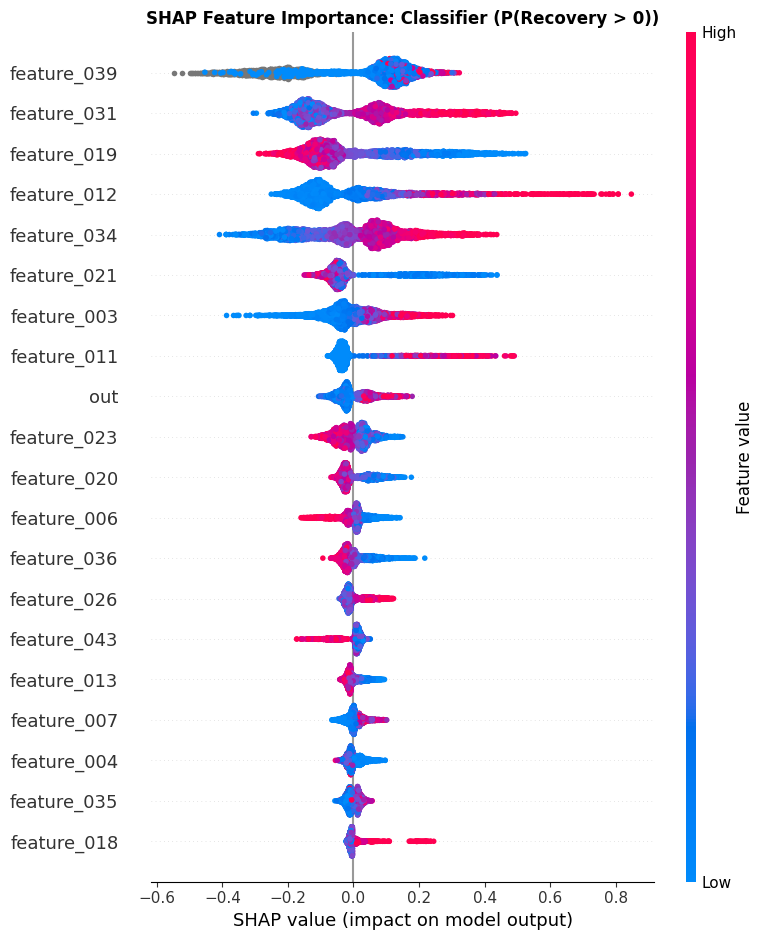

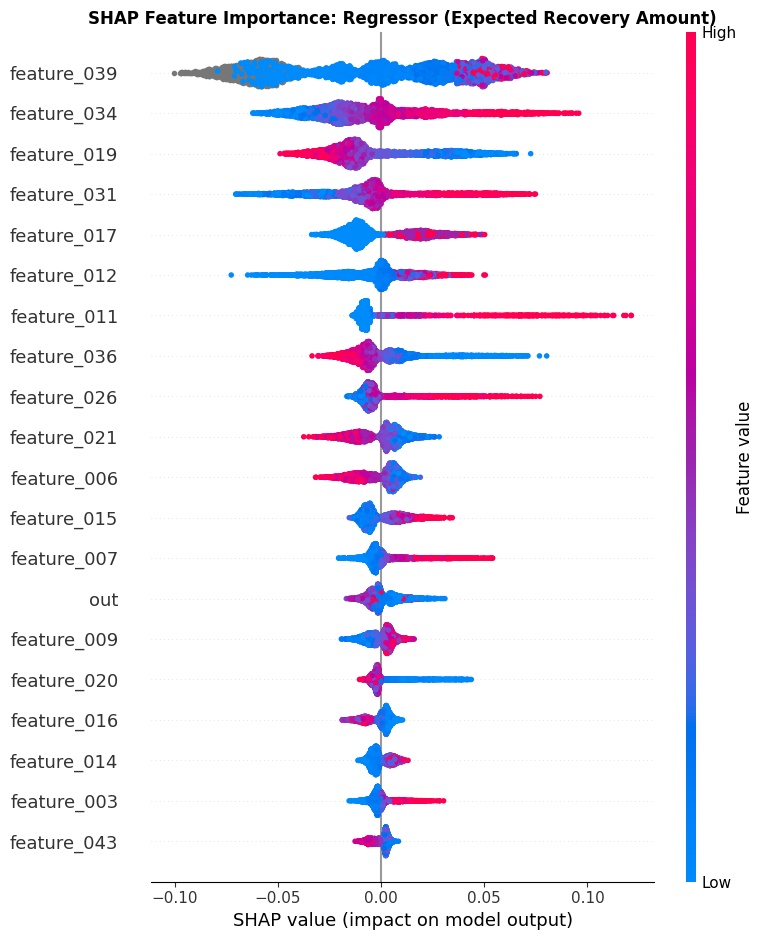

In [44]:
# SHAP INTERPRETABILITY FOR CHAMPION MODEL
import shap
import matplotlib.pyplot as plt

print("--- GENERATING SHAP EXPLAINABILITY ---")

# 1. SHAP EXPLAINER FOR CLASSIFIER (Probability of Recovery > 0)
explainer_clf = shap.TreeExplainer(clf_champ)
shap_values_clf = explainer_clf(test[FEATS])

# 2. SHAP EXPLAINER FOR REGRESSOR (Recovery Amount | Recovery > 0)
explainer_reg = shap.TreeExplainer(reg_champ)
shap_values_reg = explainer_reg(test[FEATS])

# 3. PLOT SUMMARY FOR CLASSIFIER
plt.figure(figsize=(10, 6))
plt.title("SHAP Feature Importance: Classifier (P(Recovery > 0))", fontsize=12, fontweight='bold')
shap.summary_plot(shap_values_clf, test[FEATS], plot_type="dot", show=False)
plt.tight_layout()
plt.show()

# 4. PLOT SUMMARY FOR REGRESSOR
plt.figure(figsize=(10, 6))
plt.title("SHAP Feature Importance: Regressor (Expected Recovery Amount)", fontsize=12, fontweight='bold')
shap.summary_plot(shap_values_reg, test[FEATS], plot_type="dot", show=False)
plt.tight_layout()
plt.show()

In [47]:
# SAVE FINAL CHAMPION MODEL
import joblib

model_artifacts = {
    'classifier': clf_champ,
    'regressor': reg_champ,
    'optimal_threshold': -11.5,
    'features': FEATS
}

joblib.dump(model_artifacts, 'litigation_champion_lgbm_twopart.joblib')
print("Champion model and artifacts saved successfully as 'litigation_champion_lgbm_twopart.joblib'!")

Champion model and artifacts saved successfully as 'litigation_champion_lgbm_twopart.joblib'!
